In [ ]:
# Install Requirements (run once)
!pip install pandas numpy matplotlib seaborn scikit-learn flask
# Note: sqlite3 is part of Python's standard library — no pip install needed


In [ ]:
                                #PHASE 1:Data Acquisition & SQL
#Importing csv file
import pandas as pd
import sqlite3

df=pd.read_csv('data/social_media.csv')

print("-----------------------------------Data Information-----------------------------------")
print(df.info())  #used to print the information of social_media table

#Checking the duplicate values
print("\nDuplicate Post_IDs : ")
print(df.duplicated(subset=['Post_ID']).sum())

#Checking the null values
print("\nMissing values : ")
print(df.isnull().sum())

#Converting social_media.csv into a database
conn=sqlite3.connect('social_media.db')
df.to_sql('Social_Media_Data', conn, if_exists='replace', index=False)
print("Data Imported Successfully")

#Top 5 Verified users with Highest Engagement Score
top = """SELECT Post_ID,Platform, Follower_Count, Engagement_Score FROM Social_Media_Data WHERE Verified_User = 1 ORDER BY Engagement_Score DESC LIMIT 5"""
top_verified =pd.read_sql(top, conn) 
print("\n-----------------------------------Top 5 Verified Users-----------------------------------\n",top_verified)

#Average Engagement by Platform
avg ="""SELECT Platform,AVG(Engagement_Score) AS Avg_Engagement FROM Social_Media_Data"""
avg_engagement = pd.read_sql(avg, conn)
print("\n-----------------------------------Average Engagement by Platform-----------------------------------\n",avg_engagement)

#Sentiment Distribution by Platform
sentiment ="""SELECT Platform,Sentiment_Label,COUNT(*) AS Total_Posts FROM Social_Media_Data GROUP BY Platform, Sentiment_Label ORDER BY Platform"""
sentiment_distribution = pd.read_sql(sentiment, conn) 
print("\n-----------------------------------Sentiment Distribution by Platform-----------------------------------\n",sentiment_distribution)

#Most Active Posting Hour
active = """SELECT substr(Post_Timestamp,1,2) AS Posting_Hour,COUNT(*) AS Total_Posts FROM Social_Media_Data GROUP BY Posting_Hour ORDER BY Total_Posts DESC LIMIT 1;"""
most_active = pd.read_sql(active, conn)
print("\n-----------------------------------Most Active Posting Hour-----------------------------------\n",most_active)

#Language Dominance by Platform
dominance = """SELECT Platform,Language,COUNT(*) AS Total_Posts FROM Social_Media_Data GROUP BY Platform, Language ORDER BY Platform, Total_Posts DESC;"""
language = pd.read_sql(dominance, conn)
print("\n-----------------------------------Language Dominance by Platform-----------------------------------\n",language)
conn.close()

-----------------------------------Data Information-----------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Post_ID           10000 non-null  int64  
 1   Platform          10000 non-null  str    
 2   Post_Content      10000 non-null  str    
 3   Likes             10000 non-null  int64  
 4   Shares            10000 non-null  int64  
 5   Comments_Count    10000 non-null  int64  
 6   Post_Timestamp    10000 non-null  str    
 7   Hashtags_Used     10000 non-null  int64  
 8   Follower_Count    10000 non-null  int64  
 9   Verified_User     10000 non-null  bool   
 10  Language          10000 non-null  str    
 11  Account_Age_Days  10000 non-null  int64  
 12  Sentiment_Label   10000 non-null  str    
 13  Engagement_Score  10000 non-null  float64
 14  Flagged_Content   10000 non-null  str    
dtypes: bool(1), 


-----------------------------------Correlation Heatmap-----------------------------------



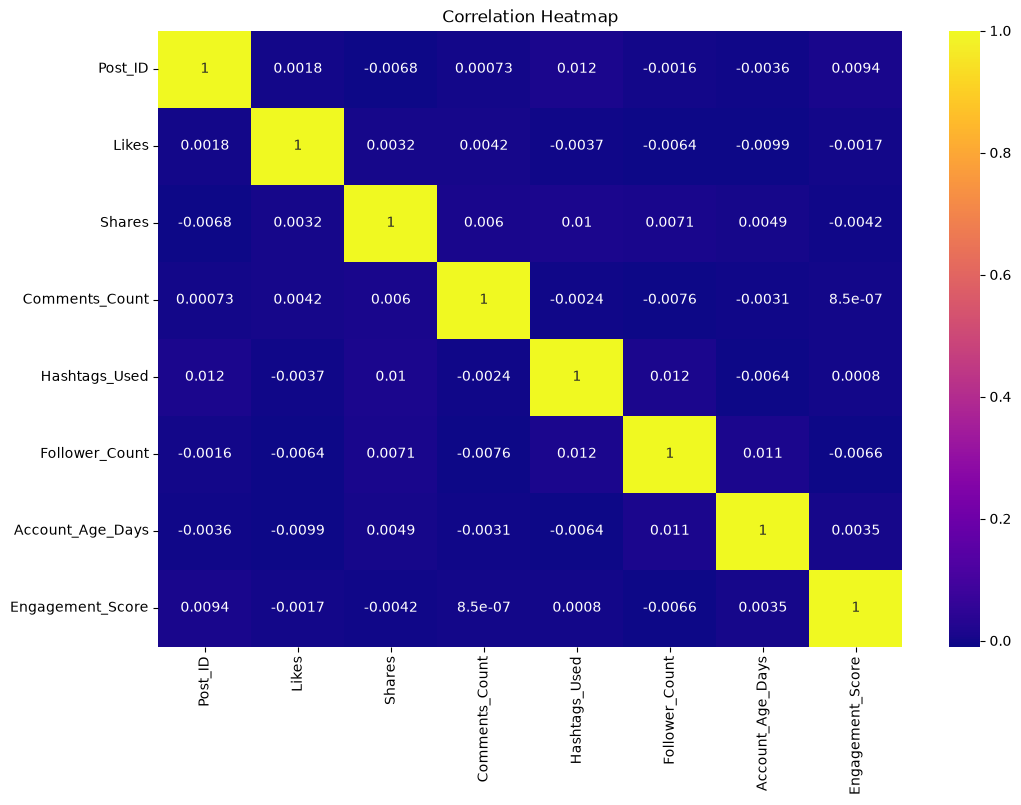


-----------------------------------Language Dominance by Platform-----------------------------------



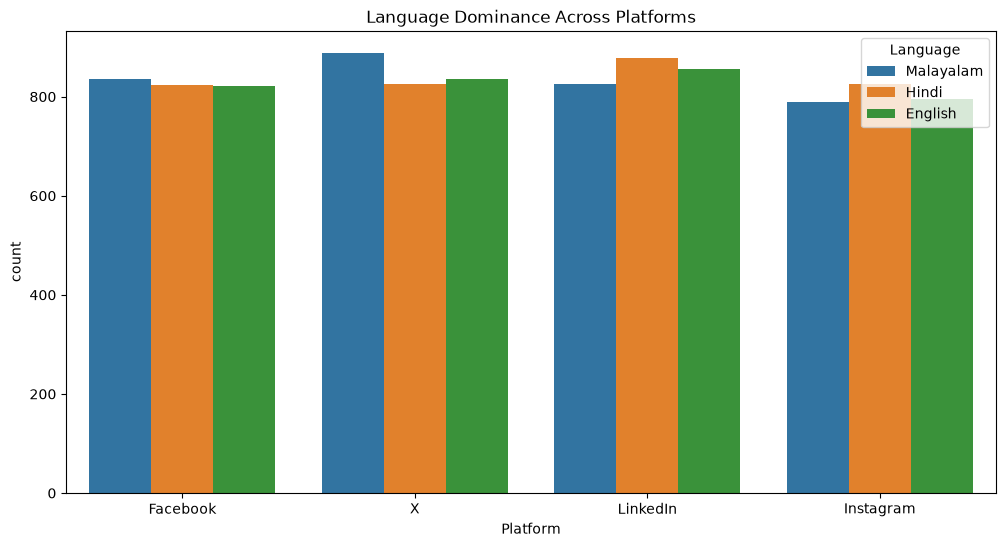


-----------------------------------Hour of Highest User Activity-----------------------------------



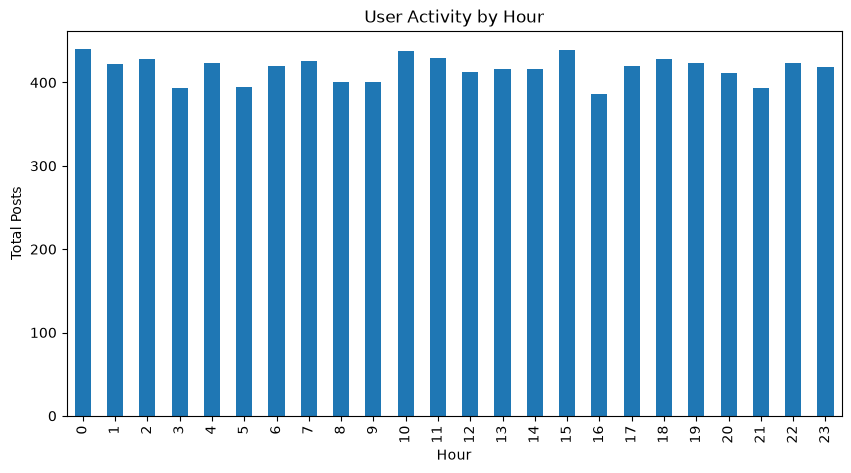


-----------------------------------Day of Week Activity-----------------------------------



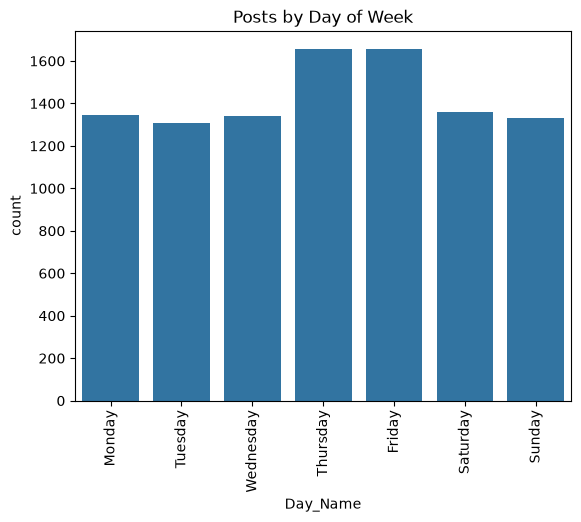


-----------------------------------Engagement vs Sentiment Analysis-----------------------------------



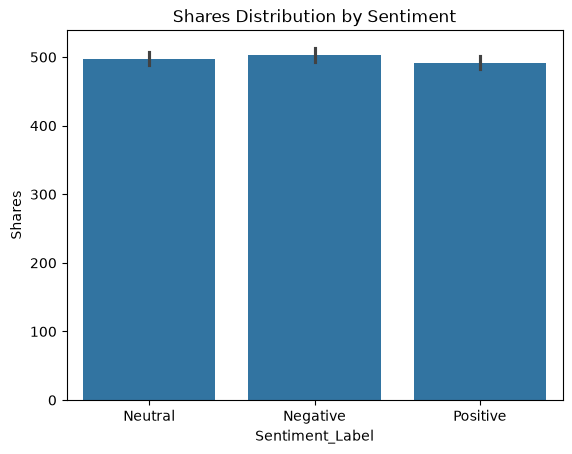

In [ ]:
                                  #PHASE 2:Exploratory Data Analysis(EDA)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df=pd.read_csv('data/social_media.csv')

#There is no missing or duplicate values are appear when i alraedy checked in the PHASE 1 but for given instruction i check both
#Filling missing categorical values with mode
df['Sentiment_Label']=df['Sentiment_Label'].fillna(df['Sentiment_Label'].mode()[0])

#Filling missing numerical values with median
df['Engagement_Score']=df['Engagement_Score'].fillna(df['Engagement_Score'].median())

#Removing outliers
q1=df['Follower_Count'].quantile(0.25)
q3=df['Follower_Count'].quantile(0.75)
ans=q3-q1
lower_bound=q1-1.5*ans
upper_bound=q3+1.5*ans
df=df[(df['Follower_Count']>=lower_bound) & (df['Follower_Count']<=upper_bound)]

#Here I can't print the dataframe it has around 1000+ data

#Correlation Heatmap
print("\n-----------------------------------Correlation Heatmap-----------------------------------\n")
numeric_df = df.select_dtypes(include=['int64', 'float64'])
plt.figure(figsize=(12,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='plasma')   #mako plasma
plt.title("Correlation Heatmap")
plt.savefig("Correlation_Heatmap.jpg", dpi=300, bbox_inches='tight')
plt.show()

#Language Dominance by Platform
print("\n-----------------------------------Language Dominance by Platform-----------------------------------\n")
plt.figure(figsize=(12,6))
sns.countplot(data=df, x='Platform', hue='Language')
plt.title("Language Dominance Across Platforms")
plt.xticks()
plt.savefig("Language Dominance by Platform.jpg", dpi=300, bbox_inches='tight')
plt.show()

# Hour of Highest User Activity
print("\n-----------------------------------Hour of Highest User Activity-----------------------------------\n")
df['Post_Timestamp'] = pd.to_datetime(df['Post_Timestamp'],dayfirst=True)
df['Hour'] = df['Post_Timestamp'].dt.hour
activity = df.groupby('Hour').size()
activity.plot(kind='bar', figsize=(10,5))
plt.title("User Activity by Hour")
plt.xlabel("Hour")
plt.ylabel("Total Posts")
plt.savefig("Hour of Highest User Activity.jpg", dpi=300, bbox_inches='tight')
plt.show()

# Day of Week Activity
print("\n-----------------------------------Day of Week Activity-----------------------------------\n")
df['Day_Name'] = df['Post_Timestamp'].dt.day_name()
sns.countplot(data=df, x='Day_Name',order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.title("Posts by Day of Week")
plt.xticks(rotation=90)
plt.savefig("Day of Week Activity.jpg", dpi=300, bbox_inches='tight')
plt.show()

#Engagement vs Sentiment Analysis
print("\n-----------------------------------Engagement vs Sentiment Analysis-----------------------------------\n")
sns.barplot(data=df, x='Sentiment_Label', y='Shares')
plt.title("Shares Distribution by Sentiment")
plt.savefig("Engagement vs Sentiment Analysis.jpg", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
                                        #PHASE 3:Model Training

#Sentiment Prediction Model using classification
print("\n-----------------------------------Sentiment Prediction Model-----------------------------------\n")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import pickle

#Load dataset
df = pd.read_csv('data/social_media.csv')

#encoding
platform = LabelEncoder()
language = LabelEncoder()
sentiment = LabelEncoder()
df['Platform'] = platform.fit_transform(df['Platform'])
df['Language'] = language.fit_transform(df['Language'])
df['Sentiment_Label'] = sentiment.fit_transform(df['Sentiment_Label'])

# Feature selection
X = df[['Platform','Likes','Shares','Comments_Count','Verified_User','Language']]
y = df['Sentiment_Label']

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
classifier = RandomForestClassifier(n_estimators=100,random_state=42)
classifier.fit(X_train, y_train)

# Predictions
predictions = classifier.predict(X_test)

# Save model
with open('models/sentiment_model.pkl','wb') as file:
    pickle.dump(classifier, file)
print("Model saved successfully in the Name of 'sentiment_model.pkl' inside the models folder")

#Save encoder
with open('models/platform_encoder.pkl', 'wb') as file:
    pickle.dump(platform, file)
print("Model saved successfully in the Name of 'platform_encoder.pkl' inside the models folder")

# Save language encoder
with open('models/language_encoder.pkl', 'wb') as file:
    pickle.dump(language, file)
print("Model saved successfully in the Name of 'language_encoder.pkl' inside the models folder")

#Engagement Score Prediction Model using Regression
print("\n-----------------------------------Engagement Score Prediction Model-----------------------------------\n")

from sklearn.ensemble import RandomForestRegressor

# Feature selection
X_reg = df[['Follower_Count','Hashtags_Used','Platform']]
y_reg = df['Engagement_Score']

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg,test_size=0.2,random_state=42)

# Train model
regressor = RandomForestRegressor(n_estimators=100,random_state=42)
regressor.fit(X_train, y_train)

# Predictions
predictions = regressor.predict(X_test)

# Save model
with open('models/engagement_model.pkl','wb') as file:
    pickle.dump(regressor,file)

print("Model saved successfully in the Name of 'engagement_model.pkl' inside the Data Analysis folder")


-----------------------------------Sentiment Prediction Model-----------------------------------

Model saved successfully in the Name of 'sentiment_model.pkl' inside the models folder
Model saved successfully in the Name of 'platform_encoder.pkl' inside the models folder
Model saved successfully in the Name of 'language_encoder.pkl' inside the models folder

-----------------------------------Engagement Score Prediction Model-----------------------------------

Model saved successfully in the Name of 'engagement_model.pkl' inside the Data Analysis folder
